# <strong>Support Vector Machines from First Principles</strong>

In this notebook, we will apply stochastic subgradient descent to optimize the primal soft-margin SVM objective.

Check out the [blog post](https://github.com/didarulilm/ml-notebooks) where I explained how to derive the optimization problem from scratch.


In [388]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

In [389]:
data = pd.read_csv("./data/non_separable_data.csv")

features = data.drop("Label", axis=1).values
labels = data["Label"].values
transformed_labels = np.where(labels == 1, 1, -1)

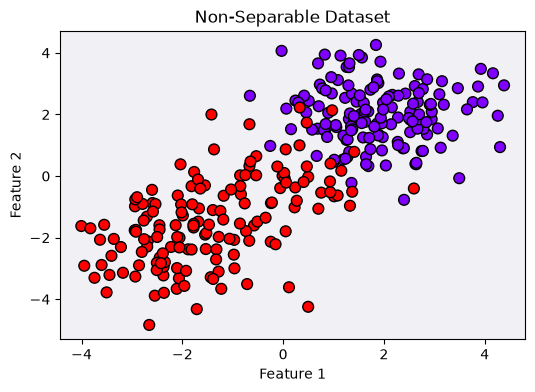

In [390]:
# Plot the dataset
plt.figure(figsize=(6, 4))

plt.gcf().patch.set_facecolor("white")
plt.gca().set_facecolor("#f0f0f5")

plt.scatter(
    features[:, 0],
    features[:, 1],
    c=(transformed_labels == 1).astype(int),    
    cmap="rainbow",
    edgecolors="black",
    s=60,
)
plt.title("Non-Separable Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### <strong>Splitting the Dataset</strong>

Let's split the dataset into 80% training and 20% test data so we can later evaluate how well the model generalizes to unseen samples.


In [391]:
# Split the dataset into training and test set
from sklearn.model_selection import train_test_split

features_train, features_test, labels_train, labels_test = train_test_split(
    features, transformed_labels, test_size=0.2, random_state=42
)

### <strong>Implementing the SVM Class</strong>

Recall that our cost function $J(w,b)$ is defined as

$$
J(w,b)={\frac{\lambda}{2}||w||^2} + \frac{1}{M}\sum_{i=1}^{M} \max(0, 1 - y_i(w^Tx_i+b))
$$

where $\lambda>0$ is the regularization parameter.

The subgradient of the cost function with respect to $w$ is given by

$$
{\nabla}_{w}J(w,b) = \lambda w + \frac{1}{M}\sum_{i=1}^{M}\begin{cases}
-  y_ix_i&\quad \text{if } y_i(w^Tx_i+b) < 1\\
0 &\quad \text{otherwise}
\end{cases}
$$

and the subgradient with respect to $b$ is given by

$$
\frac{\partial}{\partial b}J(w,b)=\frac{1}{M}\sum_{i=1}^{M}\begin{cases}
-  y_i&\quad \text{if } y_i(w^Tx_i+b) < 1\\
0 &\quad \text{otherwise}
\end{cases}
$$

For each iteration $t$, the subgradient descent update rule for minimizing the cost function $J(w,b)$ is defined as

$$
\begin{aligned}
w_{t+1} &\leftarrow w_{t} - \eta \nabla_{w}J(w_t,b_t) \\
b_{t+1} &\leftarrow b_{t} - \eta \frac{\partial}{\partial b}J(w_t,b_t) 
\end{aligned}
$$

where $0<\eta<1$ is the learning rate.

For any new point $z$, we predict the class as

$$
\hat{y}=\operatorname{sign}​(w^Tz​+b)
$$

where the $\operatorname{sign}$(·) function returns $+1$ for any positive argument, and $-1$ for any negative argument.

In [392]:
class PrimalSVM:
    def __init__(self, lambda_param):
        """
        Initialize the SVM model.
        """
        self.lambda_param = lambda_param
        self.weights = None
        self.bias = 0.0

    def _compute_cost(self, features, labels) -> float:
        """
        Compute the scalar value of the cost function.
        """
        n_samples = features.shape[0]

        # Compute the loss term
        scores = np.dot(features, self.weights) + self.bias
        y_scores = labels * scores
        hinge_loss = np.maximum(0, 1 - y_scores)
        loss_term = np.sum(hinge_loss) / n_samples

        # Compute the overall cost
        regularizer = 0.5 * self.lambda_param * np.dot(self.weights, self.weights)
        cost = regularizer + loss_term

        return float(cost)

    def _compute_subgradient(self, features, labels) -> tuple[np.ndarray, float]:
        """
        Compute the subgradient of the cost function with respect to weights and bias.
        """
        n_samples = features.shape[0]

        scores = np.dot(features, self.weights) + self.bias
        y_scores = labels * scores
        violations = y_scores < 1

        # Compute subgradients of the regularization term
        subgrad_w = self.lambda_param * self.weights
        subgrad_b = 0.0

        # Add subgradients of the loss term
        if np.any(violations):
            subgrad_w -= np.dot(features[violations].T, labels[violations]) / n_samples
            subgrad_b -= np.sum(labels[violations]) / n_samples

        return subgrad_w, subgrad_b

    def fit(self, features, labels, epochs=1000, learning_rate=0.01, batch_size=1, tol=1e-3):
        """
        Train the model with stochastic subgradient descent with support for mini-batches.
        """
        n_samples, n_features = features.shape
        self.weights = np.zeros(n_features, dtype=float)

        prev_cost = None

        # Each epoch is one full pass over the dataset
        for epoch in range(epochs):
            # Shuffle once per epoch
            indices = np.random.permutation(n_samples)
            features, labels = features[indices], labels[indices]

            # Iterate over mini-batches
            for idx in range(0, n_samples, batch_size):
                features_batch = features[idx : idx + batch_size]
                labels_batch = labels[idx : idx + batch_size]

                subgrad_w, subgrad_b = self._compute_subgradient(features_batch, labels_batch)
                self.weights -= learning_rate * subgrad_w
                self.bias -= learning_rate * subgrad_b

            curr_cost = self._compute_cost(features, labels)
            print(f"Epoch [{epoch+1}/{epochs}], Cost: {curr_cost}")

            if prev_cost is not None and abs(prev_cost - curr_cost) < tol:
                print(f"Converged at epoch {epoch + 1}")
                break
            prev_cost = curr_cost

        return self

    def predict(self, features) -> np.ndarray:
        """
        Return predicted class labels for new test samples.
        """
        if self.weights is None:
            raise ValueError("Model not trained: call fit() to set weights first.")
        labels_pred = np.dot(features, self.weights) + self.bias
        return np.sign(labels_pred)

### <strong>Training and Evaluation</strong>

First, let's train a new model and then evaluate its performance on a separate test dataset not seen during training.


In [393]:
# Train a new SVM model
lambda_param = 0.01
svm = PrimalSVM(lambda_param)
svm.fit(features_train, labels_train, epochs=100, learning_rate=0.001)

Epoch [1/100], Cost: 0.26086445795430263
Epoch [2/100], Cost: 0.21659045990346856
Epoch [3/100], Cost: 0.2023160904601288
Epoch [4/100], Cost: 0.19336604097782395
Epoch [5/100], Cost: 0.18687655817567977
Epoch [6/100], Cost: 0.18193823508570467
Epoch [7/100], Cost: 0.1772321565104322
Epoch [8/100], Cost: 0.17346370700280375
Epoch [9/100], Cost: 0.170208125106217
Epoch [10/100], Cost: 0.1675496362038084
Epoch [11/100], Cost: 0.16518752074885854
Epoch [12/100], Cost: 0.1628873722483157
Epoch [13/100], Cost: 0.16103373292020695
Epoch [14/100], Cost: 0.15921810850345663
Epoch [15/100], Cost: 0.157393879488213
Epoch [16/100], Cost: 0.1555886274450306
Epoch [17/100], Cost: 0.15378542153087935
Epoch [18/100], Cost: 0.15203885272492104
Epoch [19/100], Cost: 0.15061863313509938
Epoch [20/100], Cost: 0.14923079191142793
Epoch [21/100], Cost: 0.14783952438925627
Epoch [22/100], Cost: 0.14645459080181378
Epoch [23/100], Cost: 0.1450715249708432
Epoch [24/100], Cost: 0.1436898034572556
Epoch [25/10

In [394]:
# Predict labels for unseen test instances and evaluate the model performance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

labels_pred = svm.predict(features_test)

accuracy = accuracy_score(labels_test, labels_pred)
precision = precision_score(labels_test, labels_pred)
recall = recall_score(labels_test, labels_pred)
f1 = f1_score(labels_test, labels_pred)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Accuracy  : 0.9833
Precision : 1.0000
Recall    : 0.9677
F1 Score  : 0.9836


### <strong>Visualizing the Margin and Decision Boundary</strong>

Once training is complete, we can visualize the margin and learned decision boundary in a 2D feature space.


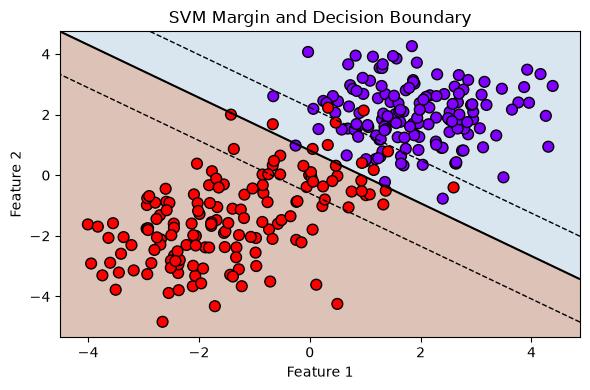

In [395]:
plt.figure(figsize=(6, 4))

plt.gcf().patch.set_facecolor("white")
plt.gca().set_facecolor("#f0f0f5")

h = 0.02
feat1_min, feat1_max = features[:, 0].min() - 0.5, features[:, 0].max() + 0.5
feat2_min, feat2_max = features[:, 1].min() - 0.5, features[:, 1].max() + 0.5

feat1_grid, feat2_grid = np.meshgrid(
    np.arange(feat1_min, feat1_max, h),
    np.arange(feat2_min, feat2_max, h),
)

grid_points = np.c_[feat1_grid.ravel(), feat2_grid.ravel()]
scores = (np.dot(grid_points, svm.weights) + svm.bias).reshape(feat1_grid.shape)

region = (scores >= 0).astype(int)
plt.contourf(feat1_grid, feat2_grid, region, cmap="Paired", alpha=0.3)

plt.contour(
    feat1_grid, feat2_grid, scores,
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1, 1.5, 1],
)

plt.scatter(
    features[:, 0],
    features[:, 1],
    c=(transformed_labels == 1).astype(int),
    cmap="rainbow",
    edgecolors="black",
    s=60,
)
plt.title("SVM Margin and Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()